# 🍼 NeoJaundice TSB Estimation — 2D CNN + MLP Fusion Model
**Architecture:** Image preprocessing → 2D CNN Visual Branch + Clinical MLP Branch → Embedding Fusion → Dual-Head (Regression + Classification)

**Dataset:** NeoJaundice Dataset (images folder + chd_jaundice.csv)

---

## 📦 Cell 1 — Install Dependencies

In [12]:
# Install required libraries
!pip install -q opencv-python-headless scikit-learn matplotlib seaborn tqdm torchinfo
print('✅ Dependencies installed')


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
✅ Dependencies installed


In [13]:
import os

# ─── CONFIGURE THESE PATHS ───────────────────────────────────────────────────
         # change if your folder is nested
IMAGES_DIR   =  "/Users/shubhbhateja/College/minor_project/database/images"       # folder with .jpg/.png images
CSV_PATH     = "/Users/shubhbhateja/College/minor_project/database/chd_jaundice_published_2.csv" # clinical metadata CSV
# ─────────────────────────────────────────────────────────────────────────────

print('Images dir exists:', os.path.isdir(IMAGES_DIR))
print('CSV exists       :', os.path.isfile(CSV_PATH))
print('Sample images    :', os.listdir(IMAGES_DIR)[:5])

Images dir exists: True
CSV exists       : True
Sample images    : ['0669-1.jpg', '0432-3.jpg', '0477-3.jpg', '1101-1.jpg', '0964-2.jpg']


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(CSV_PATH)
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
display(df.head(5))
print('\nNull counts:')
print(df.isnull().sum())
print('\nBasic stats:')
display(df.describe())

Shape: (2235, 8)

Columns: ['patient_id', 'image_idx', 'gender', 'gestational_age', 'age(day)', 'weight', 'blood(mg/dL)', 'Treatment']


,patient_id,image_idx,gender,gestational_age,age(day),weight,blood(mg/dL),Treatment
0,3,0003-1.jpg,F,40,5.2,3280,3.9,0
1,3,0003-2.jpg,F,40,5.2,3280,3.9,0
2,3,0003-3.jpg,F,40,5.2,3280,3.9,0
3,35,0035-1.jpg,M,39,8.7,3760,12.2,0
4,35,0035-2.jpg,M,39,8.7,3760,12.2,0



Null counts:
patient_id         0
image_idx          0
gender             0
gestational_age    0
age(day)           6
weight             0
blood(mg/dL)       0
Treatment          0
dtype: int64

Basic stats:


,patient_id,gestational_age,age(day),weight,blood(mg/dL),Treatment
count,2235.000000,2235.000000,2229.000000,2235.000000,2235.000000,2235.000000
mean,747.554362,38.293960,6.599192,3158.778523,11.206846,0.417450
std,420.653073,1.807409,5.703538,529.903610,5.213196,0.493249
min,1.000000,30.000000,0.100000,1690.000000,0.000000,0.000000
25%,356.000000,37.000000,2.500000,2800.000000,7.400000,0.000000
50%,794.000000,39.000000,5.000000,3180.000000,11.800000,0.000000
75%,1139.000000,40.000000,9.000000,3500.000000,15.100000,1.000000
max,1351.000000,42.000000,34.000000,5290.000000,25.700000,1.000000


## ⚙️ Cell 4 — Global Configuration

In [15]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ─── ADJUST THESE TO MATCH YOUR CSV COLUMN NAMES ─────────────────────────────
IMAGE_ID_COL    = 'image_idx'     # column with image filename (with or without extension)
TSB_COL         = 'blood(mg/dL)'  # Total Serum Bilirubin (mg/dL) — regression target
RISK_COL        = 'risk_level'    # risk category: 'Low'/'Medium'/'High' — classification target
CLINICAL_COLS   = ['weight', 'gestational_age', 'age(day)']  # clinical feature columns
# ─────────────────────────────────────────────────────────────────────────────

# Model / training config
IMG_SIZE        = 567          # resize images to IMG_SIZE x IMG_SIZE
BATCH_SIZE      = 32
EPOCHS          = 25           # Increased slightly for single split
LR              = 1e-3
WEIGHT_DECAY    = 1e-4
DROPOUT         = 0.4
PATIENCE        = 10           # early stopping patience
RISK_CLASSES    = ['Low', 'Medium', 'High']
NUM_CLASSES     = len(RISK_CLASSES)
SEED            = 42
TRAIN_SIZE      = 0.8          # 80:20 Split

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

torch.manual_seed(SEED)
np.random.seed(SEED)


Device: cpu


## 🎨 Cell 5 — Image Preprocessing Pipeline (Color Calibration + Skin Segmentation → 2D ROI)

Total images found: 2235
Preprocessed shape: (567, 567, 3), min=0.000, max=0.765


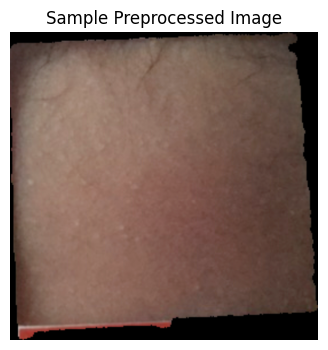

In [16]:
import cv2
import numpy as np
from pathlib import Path

def detect_hsv_card(image_bgr):
    """
    Detect HSV colour-reference card region.
    Returns a mask (or None if not found) for calibration purposes.
    Here we use a simple heuristic: look for a large rectangular
    high-saturation region in the periphery.
    """
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    # High saturation → likely colour card
    mask = cv2.inRange(hsv, (0, 150, 50), (180, 255, 255))
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask

def lab_white_balance(image_bgr):
    """Grey-world LAB white balancing."""
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    avg_a = np.mean(lab[:, :, 1])
    avg_b = np.mean(lab[:, :, 2])
    lab[:, :, 1] -= (avg_a - 128) * (lab[:, :, 0] / 255.0) * 1.1
    lab[:, :, 2] -= (avg_b - 128) * (lab[:, :, 0] / 255.0) * 1.1
    lab = np.clip(lab, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def segment_skin_roi(image_bgr):
    """
    Skin segmentation using HSV + YCrCb colour ranges.
    Returns the skin-masked image (non-skin pixels set to 0).
    """
    hsv  = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    ycr  = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YCrCb)

    mask_hsv = cv2.inRange(hsv,  (0, 15, 50),  (25, 170, 255))
    mask_ycr = cv2.inRange(ycr,  (0, 135, 85), (255, 180, 135))
    mask = cv2.bitwise_and(mask_hsv, mask_ycr)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)

    skin = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return skin, mask

def extract_roi_crop(skin_img, mask, target_size):
    """
    Find largest skin contour → crop bounding box → resize to target_size × target_size.
    Falls back to centre crop if no contour found.
    """
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        roi = skin_img[y:y+h, x:x+w]
    else:
        # Centre crop fallback
        h, w = skin_img.shape[:2]
        s = min(h, w)
        roi = skin_img[(h-s)//2:(h+s)//2, (w-s)//2:(w+s)//2]

    roi = cv2.resize(roi, (target_size, target_size))
    return roi

def preprocess_image(img_path, target_size=IMG_SIZE):
    """
    Full pipeline:
      1. Load
      2. LAB white balance
      3. Skin segmentation + ROI crop
      4. Return float32 RGB array in [0, 1]
    """
    img = cv2.imread(str(img_path))
    if img is None:
        # Return blank image on load failure
        return np.zeros((target_size, target_size, 3), dtype=np.float32)

    img = lab_white_balance(img)
    skin, mask = segment_skin_roi(img)

    # If skin mask is nearly empty, use the whole image
    if mask.sum() < 500:
        roi = cv2.resize(img, (target_size, target_size))
    else:
        roi = extract_roi_crop(skin, mask, target_size)

    roi = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    return roi.astype(np.float32) / 255.0

# ─── Quick sanity-check on one image ─────────────────────────────────────────
sample_files = list(Path(IMAGES_DIR).glob('*'))
sample_files = [f for f in sample_files if f.suffix.lower() in ('.jpg','.jpeg','.png')]
print(f'Total images found: {len(sample_files)}')

if sample_files:
    test_img = preprocess_image(sample_files[140])
    print(f'Preprocessed shape: {test_img.shape}, min={test_img.min():.3f}, max={test_img.max():.3f}')
    plt.figure(figsize=(4, 4))
    plt.imshow(test_img)
    plt.title('Sample Preprocessed Image')
    plt.axis('off')
    plt.show()

## 🗂️ Cell 6 — Data Preparation & Label Encoding

In [17]:
# Create the 'risk_level' column by binning the Total Serum Bilirubin values
def assign_risk(tsb_value):
    if tsb_value < 7.0:         # You can adjust these medical thresholds
        return 'Low'
    elif tsb_value <= 15.0:
        return 'Medium'
    else:
        return 'High'

# Apply the function to create the column
df['risk_level'] = df['blood(mg/dL)'].apply(assign_risk)

print("Created risk_level column!")
print(df['risk_level'].value_counts())


Created risk_level column!
risk_level
Medium    1149
High       588
Low        498
Name: count, dtype: int64


Clean rows: 2229
Missing image files: 0
Rows with valid images: 2229
Risk class mapping: {np.str_('Low'): np.int64(0), np.str_('Medium'): np.int64(1), np.str_('High'): np.int64(2)}


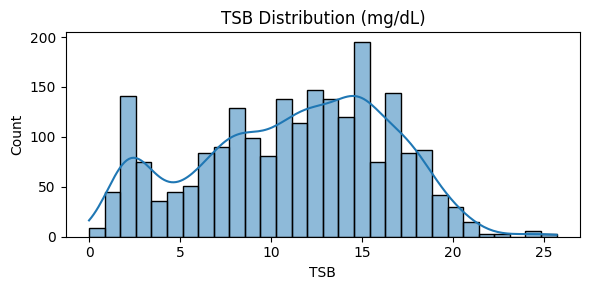


Risk class distribution:
risk_level
Medium    1149
High       585
Low        495
Name: count, dtype: int64


In [18]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from pathlib import Path

def find_image_path(img_id, images_dir):
    """Resolve image filename with or without extension."""
    images_dir = Path(images_dir)
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        p = images_dir / f'{img_id}{ext}'
        if p.exists():
            return p
        p2 = images_dir / str(img_id)
        if p2.exists():
            return p2
    return None

# ─── Drop rows with missing targets ──────────────────────────────────────────
df = df.dropna(subset=[IMAGE_ID_COL, TSB_COL, RISK_COL] + CLINICAL_COLS).reset_index(drop=True)
print(f'Clean rows: {len(df)}')

# ─── Resolve image paths ──────────────────────────────────────────────────────
df['img_path'] = df[IMAGE_ID_COL].apply(lambda x: find_image_path(x, IMAGES_DIR))
missing = df['img_path'].isna().sum()
print(f'Missing image files: {missing}')
df = df[df['img_path'].notna()].reset_index(drop=True)
print(f'Rows with valid images: {len(df)}')

# ─── Normalise clinical features ─────────────────────────────────────────────
scaler = MinMaxScaler()
df[CLINICAL_COLS] = scaler.fit_transform(df[CLINICAL_COLS].values.astype(np.float32))

# ─── Encode risk labels ───────────────────────────────────────────────────────
le = LabelEncoder()
le.classes_ = np.array(RISK_CLASSES)
df['risk_encoded'] = le.transform(df[RISK_COL].str.strip())
print('Risk class mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

# ─── TSB distribution ─────────────────────────────────────────────────────────
plt.figure(figsize=(6, 3))
sns.histplot(df[TSB_COL], bins=30, kde=True)
plt.title('TSB Distribution (mg/dL)')
plt.xlabel('TSB')
plt.tight_layout()
plt.show()

print('\nRisk class distribution:')
print(df[RISK_COL].value_counts())

## 🔥 Cell 7 — PyTorch Dataset & Augmentation

In [19]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# ─── Standard transforms (No Augmentation) ──────────────────────────────────
val_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std =[0.229, 0.224, 0.225]),
])

train_transform = val_transform  # Use same transform for training (no augmentation)


class JaundiceDataset(Dataset):
    def __init__(self, dataframe, transform=None, img_size=IMG_SIZE):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform
        self.img_size  = img_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # ── Image ──────────────────────────────────────────────────────────────
        img = preprocess_image(row['img_path'], self.img_size)  # H×W×3, float32 [0,1]
        img = (img * 255).astype(np.uint8)                       # back to uint8 for transforms
        if self.transform:
            img = self.transform(img)                             # → C×H×W tensor
        else:
            img = torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0

        # ── Clinical features ──────────────────────────────────────────────────
        clinical = torch.tensor(row[CLINICAL_COLS].values.astype(np.float32))

        # ── Targets ────────────────────────────────────────────────────────────
        tsb  = torch.tensor(float(row[TSB_COL]),         dtype=torch.float32)
        risk = torch.tensor(int(row['risk_encoded']),    dtype=torch.long)

        return img, clinical, tsb, risk


# ─── Quick shape test ─────────────────────────────────────────────────────────
dummy_ds = JaundiceDataset(df.head(4), transform=val_transform)
img, clin, tsb, risk = dummy_ds[0]
print(f'Image tensor : {img.shape}')
print(f'Clinical     : {clin.shape}')
print(f'TSB          : {tsb}')
print(f'Risk         : {risk}')


Image tensor : torch.Size([3, 567, 567])
Clinical     : torch.Size([3])
TSB          : 3.9000000953674316
Risk         : 0


## 🧠 Cell 8 — Model Architecture (2D CNN Visual Branch + MLP Clinical Branch + Dual Head)

In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary


# ──────────────────────────────────────────────────────────────────────────────
# 2D CNN Visual Branch
# ──────────────────────────────────────────────────────────────────────────────
class VisualBranch2DCNN(nn.Module):
    """
    Visual Branch using stacked Conv2D blocks (replacing 1D CNN).
    Architecture: Conv2D → BN → ReLU → MaxPool  (×N blocks) → GlobalAvgPool → FC → visual_embedding
    """
    def __init__(self, embedding_dim=256, dropout=DROPOUT):
        super().__init__()

        # ── Block 1 ────────────────────────────────────────────────────────────
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          
            nn.Dropout2d(0.1),
        )

        # ── Block 2 ────────────────────────────────────────────────────────────
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),         
            nn.Dropout2d(0.1),
        )

        # ── Block 3 ────────────────────────────────────────────────────────────
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          
            nn.Dropout2d(0.2),
        )

        # ── Block 4 ────────────────────────────────────────────────────────────
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          
            nn.Dropout2d(0.2),
        )

        # ── Global Average Pool → Embedding ────────────────────────────────────
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))  
        self.embedding   = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        x = self.embedding(x)
        return x   # shape: (B, embedding_dim)


# ──────────────────────────────────────────────────────────────────────────────
# MLP Clinical Branch
# ──────────────────────────────────────────────────────────────────────────────
class ClinicalBranchMLP(nn.Module):
    """
    Clinical Branch: normalised clinical parameters → MLP → clinical_embedding
    """
    def __init__(self, input_dim, embedding_dim=64, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            # Layer 1
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            # Layer 2
            nn.Linear(128, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)   # shape: (B, embedding_dim)


# ──────────────────────────────────────────────────────────────────────────────
# Fusion Model — Dual Head
# ──────────────────────────────────────────────────────────────────────────────
class NeoJaundiceFusionModel(nn.Module):
    """
    Full architecture:
      VisualBranch2DCNN + ClinicalBranchMLP
      → Concatenate embeddings
      → Shared FC + Dropout
      → Regression Head (TSB in mg/dL)
      → Classification Head (Low / Medium / High)
    """
    def __init__(self,
                 clinical_input_dim,
                 visual_emb_dim  = 256,
                 clinical_emb_dim = 64,
                 num_classes      = NUM_CLASSES,
                 dropout          = DROPOUT):
        super().__init__()

        self.visual_branch   = VisualBranch2DCNN(embedding_dim=visual_emb_dim,   dropout=dropout)
        self.clinical_branch = ClinicalBranchMLP(input_dim=clinical_input_dim,
                                                  embedding_dim=clinical_emb_dim, dropout=dropout)

        fused_dim = visual_emb_dim + clinical_emb_dim

        # ── Shared Fusion FC ───────────────────────────────────────────────────
        self.fusion = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

        # ── Regression Head ────────────────────────────────────────────────────
        self.regression_head    = nn.Linear(128, 1)

        # ── Classification Head ────────────────────────────────────────────────
        self.classification_head = nn.Linear(128, num_classes)

    def forward(self, img, clinical):
        vis_emb  = self.visual_branch(img)       # (B, visual_emb_dim)
        clin_emb = self.clinical_branch(clinical) # (B, clinical_emb_dim)

        fused    = torch.cat([vis_emb, clin_emb], dim=1)  # (B, fused_dim)
        shared   = self.fusion(fused)                     # (B, 128)

        tsb_pred  = self.regression_head(shared).squeeze(1)    # (B,)
        risk_pred = self.classification_head(shared)            # (B, num_classes)

        return tsb_pred, risk_pred


# ─── Instantiate & inspect ────────────────────────────────────────────────────
model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)

print(model)
print('\n--- Model Summary ---')
summary(model,
        input_data=[torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE),
                    torch.randn(2, len(CLINICAL_COLS)).to(DEVICE)],
        verbose=1)

NeoJaundiceFusionModel(
  (visual_branch): VisualBranch2DCNN(
    (block1): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.1, inplace=False)
    )
    (block2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e

Layer (type:depth-idx)                   Output Shape              Param #
NeoJaundiceFusionModel                   [2]                       --
├─VisualBranch2DCNN: 1-1                 [2, 256]                  --
│    └─Sequential: 2-1                   [2, 32, 283, 283]         --
│    │    └─Conv2d: 3-1                  [2, 32, 567, 567]         864
│    │    └─BatchNorm2d: 3-2             [2, 32, 567, 567]         64
│    │    └─ReLU: 3-3                    [2, 32, 567, 567]         --
│    │    └─Conv2d: 3-4                  [2, 32, 567, 567]         9,216
│    │    └─BatchNorm2d: 3-5             [2, 32, 567, 567]         64
│    │    └─ReLU: 3-6                    [2, 32, 567, 567]         --
│    │    └─MaxPool2d: 3-7               [2, 32, 283, 283]         --
│    │    └─Dropout2d: 3-8               [2, 32, 283, 283]         --
│    └─Sequential: 2-2                   [2, 64, 141, 141]         --
│    │    └─Conv2d: 3-9                  [2, 64, 283, 283]         18,432
│    │ 

## 🏋️ Cell 9 — Training & Validation Functions

In [21]:
import torch.optim as optim
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter


class EarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.best_score = None
        self.counter    = 0
        self.best_state = None
        self.stopped    = False

    def step(self, val_loss, model):
        score = -val_loss
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter    = 0
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stopped = True

    def restore_best(self, model):
        if self.best_state:
            model.load_state_dict(self.best_state)


def train_one_epoch(model, loader, optimizer, reg_criterion, cls_criterion, 
                    writer=None, global_step=0, reg_weight=0.5):
    model.train()
    total_loss = total_reg = total_cls = 0

    for imgs, clinical, tsb, risk in tqdm(loader, leave=False, desc='Train'):
        imgs, clinical = imgs.to(DEVICE), clinical.to(DEVICE)
        tsb, risk       = tsb.to(DEVICE),  risk.to(DEVICE)

        optimizer.zero_grad()
        tsb_pred, risk_pred = model(imgs, clinical)

        loss_reg = reg_criterion(tsb_pred,  tsb)
        loss_cls = cls_criterion(risk_pred, risk)
        loss     = reg_weight * loss_reg + (1 - reg_weight) * loss_cls

        loss.backward()
        
        # ── Global Gradient Norm ──────────────────────────────────────────────
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()

        total_loss += loss.item()
        total_reg  += loss_reg.item()
        total_cls  += loss_cls.item()
        
        # ── TensorBoard Logging per iteration ─────────────────────────────────
        if writer:
            writer.add_scalar('Iter/Total_Loss', loss.item(), global_step)
            writer.add_scalar('Iter/Reg_Loss', loss_reg.item(), global_step)
            writer.add_scalar('Iter/Cls_Loss', loss_cls.item(), global_step)
            writer.add_scalar('Iter/Grad_Norm', grad_norm.item(), global_step)
            
        global_step += 1

    n = len(loader)
    return total_loss/n, total_reg/n, total_cls/n, global_step


@torch.no_grad()
def validate(model, loader, reg_criterion, cls_criterion, reg_weight=0.5):
    model.eval()
    total_loss = total_reg = total_cls = 0
    all_tsb_true, all_tsb_pred = [], []
    all_risk_true, all_risk_pred = [], []

    for imgs, clinical, tsb, risk in tqdm(loader, leave=False, desc='Val'):
        imgs, clinical = imgs.to(DEVICE), clinical.to(DEVICE)
        tsb, risk       = tsb.to(DEVICE),  risk.to(DEVICE)

        tsb_pred, risk_pred = model(imgs, clinical)

        loss_reg = reg_criterion(tsb_pred,  tsb)
        loss_cls = cls_criterion(risk_pred, risk)
        loss     = reg_weight * loss_reg + (1 - reg_weight) * loss_cls

        total_loss += loss.item()
        total_reg  += loss_reg.item()
        total_cls  += loss_cls.item()

        all_tsb_true.extend(tsb.cpu().numpy())
        all_tsb_pred.extend(tsb_pred.cpu().numpy())
        all_risk_true.extend(risk.cpu().numpy())
        all_risk_pred.extend(risk_pred.argmax(dim=1).cpu().numpy())

    n = len(loader)
    return (total_loss/n, total_reg/n, total_cls/n,
            np.array(all_tsb_true), np.array(all_tsb_pred),
            np.array(all_risk_true), np.array(all_risk_pred))


print('✅ Training functions defined with TensorBoard support')


✅ Training functions defined with TensorBoard support


## 🔄 Cell 10 — Stratified K-Fold Cross-Validation Training

In [22]:
# ─── Launch TensorBoard ───────────────────────────────────────────────────────
%load_ext tensorboard
%tensorboard --logdir runs


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, 
                              recall_score, f1_score, r2_score)

def compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred):
    rmse = np.sqrt(np.mean((tsb_true - tsb_pred)**2))
    r2   = r2_score(tsb_true, tsb_pred)
    acc  = accuracy_score(risk_true, risk_pred)
    prec = precision_score(risk_true, risk_pred, average='weighted', zero_division=0)
    rec  = recall_score(risk_true,    risk_pred, average='weighted', zero_division=0)
    f1   = f1_score(risk_true,        risk_pred, average='weighted', zero_division=0)
    return dict(RMSE=rmse, R2=r2, Accuracy=acc, Precision=prec, Recall=rec, F1=f1)

# ─── Strict 80:20 Train/Test Split ───────────────────────────────────────────
train_df, test_df = train_test_split(
    df, 
    test_size=1-TRAIN_SIZE, 
    stratify=df['risk_encoded'], 
    random_state=SEED
)

print(f'Split complete: Train={len(train_df)}, Test={len(test_df)} (strictly isolated)')

# ─── DataLoaders ─────────────────────────────────────────────────────────────
train_ds = JaundiceDataset(train_df, transform=train_transform)
test_ds  = JaundiceDataset(test_df,  transform=val_transform)

# set pin_memory=False for CPU-friendly execution
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

# ─── Model, Optimizer, Scheduler ─────────────────────────────────────────────
model     = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS), visual_emb_dim=256).to(DEVICE)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

reg_crit = nn.MSELoss()
cls_crit = nn.CrossEntropyLoss()

# ─── TensorBoard Setup ───────────────────────────────────────────────────────
writer = SummaryWriter(log_dir='runs/neojaundice_experiment')
global_step = 0

history = {'train_loss':[], 'train_reg':[], 'train_cls':[]}

print(f"\n{'='*60}")
print(f"STARTING TRAINING (80% Training Set Only)")
print(f"{'='*60}")

# ── Epoch loop ────────────────────────────────────────────────────────────
for epoch in range(1, EPOCHS+1):
    # Model sees ONLY train_dl during training
    tr_loss, tr_reg, tr_cls, global_step = train_one_epoch(
        model, train_dl, optimizer, reg_crit, cls_crit, 
        writer=writer, global_step=global_step
    )
    
    scheduler.step()
    
    # Log epoch-level scalars
    writer.add_scalar('Epoch/Loss', tr_loss, epoch)
    
    history['train_loss'].append(tr_loss)
    history['train_reg'].append(tr_reg)
    history['train_cls'].append(tr_cls)
    
    if epoch % 1 == 0 or epoch == 1:
        print(f'  Epoch {epoch:3d}/{EPOCHS} | Train Loss={tr_loss:.4f} | Reg={tr_reg:.4f} | Cls={tr_cls:.4f}')

# ── Final evaluation on the 20% Test Set ──────────────────────────────────
print(f'\n🔎 Final Evaluation on isolated Test Set...')
test_out = validate(model, test_dl, reg_crit, cls_crit)
ts_loss, ts_reg, ts_cls, tsb_true, tsb_pred, risk_true, risk_pred = test_out

final_metrics = compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred)

writer.add_hparams(
    {'lr': LR, 'bsize': BATCH_SIZE, 'epochs': EPOCHS, 'dropout': DROPOUT},
    {'hparams/RMSE': final_metrics['RMSE'], 'hparams/F1': final_metrics['F1']}
)

writer.close()

print(f'\n✅ Training Complete')
print(f'Final Test Metrics: {final_metrics}')


Split complete: Train=1783, Test=446 (strictly isolated)

STARTING TRAINING (80% Training Set Only)


  Epoch   1/25 | Train Loss=56.0094 | Reg=110.9848 | Cls=1.0340


  Epoch   2/25 | Train Loss=25.1438 | Reg=49.4610 | Cls=0.8267


  Epoch   3/25 | Train Loss=10.7922 | Reg=20.7304 | Cls=0.8541


  Epoch   4/25 | Train Loss=7.4517 | Reg=14.1093 | Cls=0.7942


  Epoch   5/25 | Train Loss=7.3702 | Reg=13.9592 | Cls=0.7812


Train:  61%|██████    | 34/56 [15:19<11:06, 30.29s/it]

In [1]:
import pandas as pd

metrics_df = pd.DataFrame([final_metrics])
print('\n📋 Final Model Performance (Test Set):')
display(metrics_df.round(4))

# ─── Training Curves ──────────────────────────────────────────────────────────
plt.figure(figsize=(12, 4))

# Plot total train loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Total Train Loss', color='steelblue')
plt.title('Training Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot breakdown
plt.subplot(1, 2, 2)
plt.plot(history['train_reg'], label='Train Reg (MSE)', color='salmon')
plt.plot(history['train_cls'], label='Train Cls (CE)', color='green')
plt.title('Loss Component Breakdown')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


NameError: name 'final_metrics' is not defined

## 📈 Cell 12 — Training Curves (Loss per Fold)

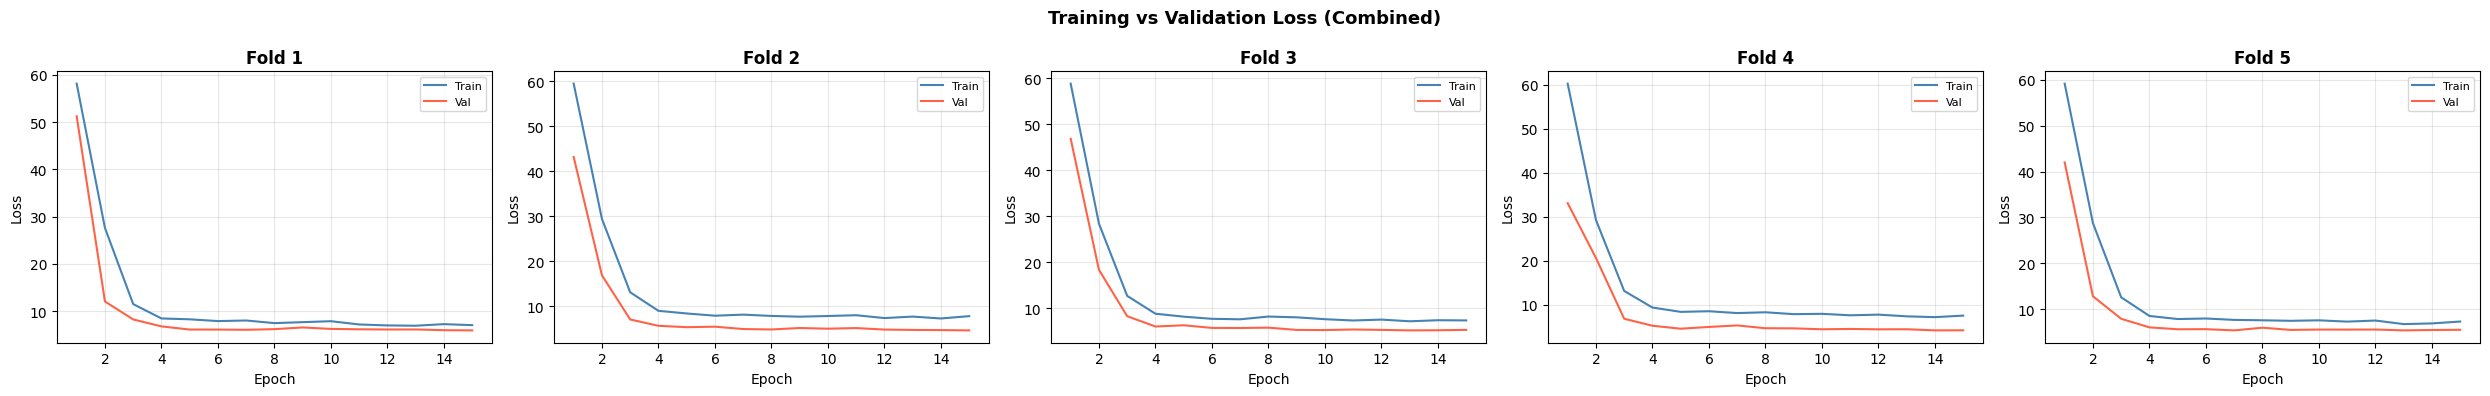

In [ ]:
fig, axes = plt.subplots(1, N_FOLDS, figsize=(5*N_FOLDS, 4), sharey=False)

for fold_idx, (hist, ax) in enumerate(zip(all_histories, axes)):
    ep = range(1, len(hist['train_loss'])+1)
    ax.plot(ep, hist['train_loss'], label='Train', color='steelblue')
    ax.plot(ep, hist['val_loss'],   label='Val',   color='tomato')
    ax.set_title(f'Fold {fold_idx+1}', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Training vs Validation Loss (Combined)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 🧪 Cell 13 — Final Evaluation on Best Model (70/10/20 Split)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# ─── 70 / 10 / 20 split ──────────────────────────────────────────────────────
df_train_val, df_test = train_test_split(df, test_size=0.20, stratify=df['risk_encoded'], random_state=SEED)
df_train, df_val      = train_test_split(df_train_val, test_size=0.125,  # 0.125 × 0.80 = 0.10
                                          stratify=df_train_val['risk_encoded'], random_state=SEED)
print(f'Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')

# ─── Reload best model ────────────────────────────────────────────────────────
final_model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)
final_model.load_state_dict({k: v.to(DEVICE) for k, v in best_model_state.items()})

# ─── Test DataLoader ─────────────────────────────────────────────────────────
test_ds = JaundiceDataset(df_test, transform=val_transform)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

reg_crit = nn.MSELoss()
cls_crit = nn.CrossEntropyLoss()

# # tsb_true, tsb_pred, risk_true, risk_pred = validate(final_model, test_dl, reg_crit, cls_crit)
# # Temporarily catch all results in one variable
# results = validate(final_model, test_dl, reg_crit, cls_crit)

# # Check how many items it actually returns
# print(f"The validate function returned {len(results)} items.")
_, _, _, tsb_true, tsb_pred, risk_true, risk_pred = validate(final_model, test_dl, reg_crit, cls_crit)



test_metrics = compute_metrics(tsb_true, tsb_pred, risk_true, risk_pred)
print('\n📊 TEST SET RESULTS')
print('='*40)
for k, v in test_metrics.items():
    print(f'  {k:<12}: {v:.4f}')
print('='*40)

Train: 1560 | Val: 223 | Test: 446


Val:   0%|          | 0/14 [00:00<?, ?it/s]


📊 TEST SET RESULTS
  RMSE        : 2.9703
  R2          : 0.6770
  Accuracy    : 0.6682
  Precision   : 0.7325
  Recall      : 0.6682
  F1          : 0.5967


## 🔍 Cell 14 — Confusion Matrix & Classification Report

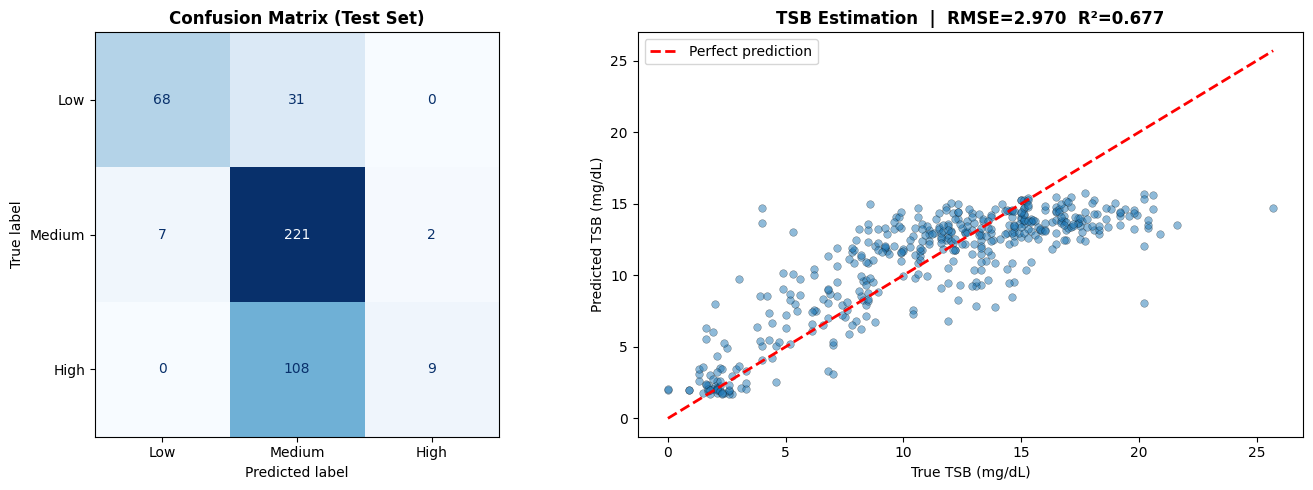


📋 Classification Report:
              precision    recall  f1-score   support

         Low       0.91      0.69      0.78        99
      Medium       0.61      0.96      0.75       230
        High       0.82      0.08      0.14       117

    accuracy                           0.67       446
   macro avg       0.78      0.57      0.56       446
weighted avg       0.73      0.67      0.60       446



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ─── Confusion Matrix ─────────────────────────────────────────────────────────
cm = confusion_matrix(risk_true, risk_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=RISK_CLASSES)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix (Test Set)', fontweight='bold')

# ─── TSB Scatter: True vs Predicted ──────────────────────────────────────────
axes[1].scatter(tsb_true, tsb_pred, alpha=0.5, edgecolors='k', linewidths=0.3, s=30)
mn, mx = min(tsb_true.min(), tsb_pred.min()), max(tsb_true.max(), tsb_pred.max())
axes[1].plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect prediction')
axes[1].set_xlabel('True TSB (mg/dL)')
axes[1].set_ylabel('Predicted TSB (mg/dL)')
axes[1].set_title(f'TSB Estimation  |  RMSE={test_metrics["RMSE"]:.3f}  R²={test_metrics["R2"]:.3f}',
                   fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print('\n📋 Classification Report:')
print(classification_report(risk_true, risk_pred, target_names=RISK_CLASSES))

## 🌡️ Cell 15 — TSB Error Distribution & Residuals

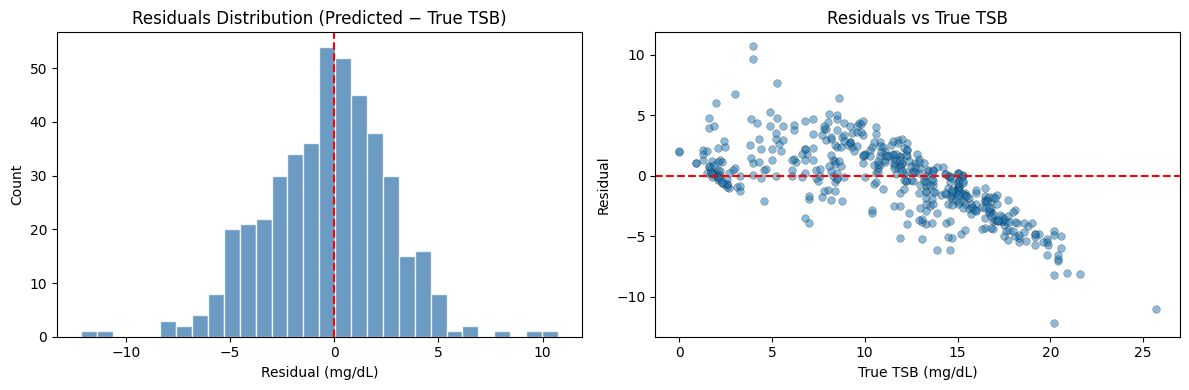

Mean Error   : -0.3375 mg/dL
Std Error    : 2.9510 mg/dL
Max Abs Error: 12.1537 mg/dL


In [ ]:
residuals = tsb_pred - tsb_true

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residuals histogram
axes[0].hist(residuals, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Residuals Distribution (Predicted − True TSB)')
axes[0].set_xlabel('Residual (mg/dL)')
axes[0].set_ylabel('Count')

# Residuals vs True TSB
axes[1].scatter(tsb_true, residuals, alpha=0.5, edgecolors='k', linewidths=0.3, s=30)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs True TSB')
axes[1].set_xlabel('True TSB (mg/dL)')
axes[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

print(f'Mean Error   : {residuals.mean():.4f} mg/dL')
print(f'Std Error    : {residuals.std():.4f} mg/dL')
print(f'Max Abs Error: {np.abs(residuals).max():.4f} mg/dL')

## 💾 Cell 16 — Save Model & Results

In [ ]:
import json

# ─── Save model checkpoint ────────────────────────────────────────────────────
SAVE_DIR = "C:/Users/pujaj/OneDrive/Desktop/Minor/NeoJaundice/NeoJaundice/saved_model"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint = {
    'model_state_dict': best_model_state,
    'config': {
        'IMG_SIZE': IMG_SIZE,
        'CLINICAL_COLS': CLINICAL_COLS,
        'RISK_CLASSES': RISK_CLASSES,
        'visual_emb_dim': 256,
        'clinical_emb_dim': 64,
    }
}
torch.save(checkpoint, os.path.join(SAVE_DIR, 'best_model.pth'))
print('✅ Model saved:', os.path.join(SAVE_DIR, 'best_model.pth'))

# ─── Save metrics to CSV ──────────────────────────────────────────────────────
results_df.to_csv(os.path.join(SAVE_DIR, 'fold_metrics.csv'))

# Save test metrics as JSON
with open(os.path.join(SAVE_DIR, 'test_metrics.json'), 'w') as f:
    json.dump({k: float(v) for k, v in test_metrics.items()}, f, indent=2)

print('✅ Metrics saved to', SAVE_DIR)
print('\nFinal Test Metrics Summary:')
print(json.dumps({k: round(float(v), 4) for k, v in test_metrics.items()}, indent=2))

✅ Model saved: C:/Users/pujaj/OneDrive/Desktop/Minor/NeoJaundice/NeoJaundice/saved_model\best_model.pth
✅ Metrics saved to C:/Users/pujaj/OneDrive/Desktop/Minor/NeoJaundice/NeoJaundice/saved_model

Final Test Metrics Summary:
{
  "RMSE": 2.9703,
  "R2": 0.677,
  "Accuracy": 0.6682,
  "Precision": 0.7325,
  "Recall": 0.6682,
  "F1": 0.5967
}


## 🔮 Cell 17 — Single Image Inference (Demo)
Use this cell to run inference on any single image + clinical values.

In [ ]:
import torch
# 1. Recreate the blank model architecture
final_model = NeoJaundiceFusionModel(clinical_input_dim=len(CLINICAL_COLS)).to(DEVICE)

# 2. Load the entire checkpoint dictionary from the file
checkpoint = torch.load('saved_model/best_model.pth', map_location=DEVICE)

# 3. Inject ONLY the model_state_dict part into the model architecture
final_model.load_state_dict(checkpoint['model_state_dict'])

# 4. Set to evaluation mode
final_model.eval()  

print("Model successfully reloaded without retraining!")



Model successfully reloaded without retraining!


🔮 Inference result:
  TSB_predicted_mg_dL: 5.90308952331543
  Risk_class: Low
  Risk_probabilities: {np.str_('Low'): 0.564247190952301, np.str_('Medium'): 0.3402947187423706, np.str_('High'): 0.09545816481113434}


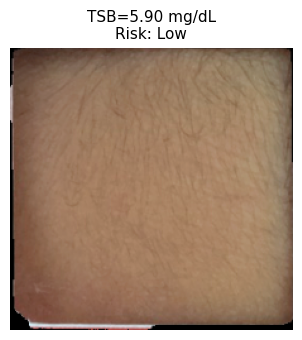

In [ ]:
def predict_single(img_path, clinical_values_raw, model, scaler, le, transform=val_transform):
    """
    Predict TSB and risk for a single sample.

    Args:
        img_path          : path to the image file
        clinical_values_raw: list of raw (un-normalised) values matching CLINICAL_COLS order
        model             : trained NeoJaundiceFusionModel
        scaler            : fitted MinMaxScaler
        le                : fitted LabelEncoder
        transform         : image transform

    Returns: dict with TSB prediction and risk class
    """
    model.eval()

    # Image
    img = preprocess_image(img_path)
    img = (img * 255).astype(np.uint8)
    img_tensor = transform(img).unsqueeze(0).to(DEVICE)   # 1×C×H×W

    # Clinical
    clin_raw  = np.array(clinical_values_raw, dtype=np.float32).reshape(1, -1)
    clin_norm = scaler.transform(clin_raw)
    clin_tensor = torch.tensor(clin_norm, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        tsb_pred, risk_logits = model(img_tensor, clin_tensor)
        risk_idx  = risk_logits.argmax(dim=1).item()
        risk_prob = torch.softmax(risk_logits, dim=1).squeeze().cpu().numpy()

    return {
        'TSB_predicted_mg_dL': float(tsb_pred.item()),
        'Risk_class'         : le.classes_[risk_idx],
        'Risk_probabilities' : dict(zip(le.classes_, risk_prob.tolist())),
    }


# ─── Demo on first available image ────────────────────────────────────────────
if sample_files:
    example_clinical = [2.5, 34, 3]  # ← replace with actual values: weight, gestational_age, postnatal_age
    result = predict_single(sample_files[0], example_clinical, final_model, scaler, le)

    print('🔮 Inference result:')
    for k, v in result.items():
        print(f'  {k}: {v}')

    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(preprocess_image(sample_files[0]))
    plt.title(f'TSB={result["TSB_predicted_mg_dL"]:.2f} mg/dL\nRisk: {result["Risk_class"]}',
              fontsize=11)
    plt.axis('off')
    plt.tight_layout()
    plt.show()